In [1]:
import pandas as pd

# Load the merged dataset
final_heritage_data = pd.read_csv(
    "../data/processed/final_heritage_jan_2026.csv"
)

print("Initial total sites:", len(final_heritage_data))
print("Sites with missing views:", final_heritage_data["total_views"].isna().sum())
print("Sites with views:", final_heritage_data["total_views"].notna().sum())



print("\nAfter excluding sites inscribed after 2025:")
print("Sites remaining:", len(final_heritage_data))

# Remove sites without pageview data
final_heritage_data = final_heritage_data[
    final_heritage_data["total_views"].notna()
].copy()

print("\nAfter removing sites without pageviews:")
print("Sites remaining:", len(final_heritage_data))
print("Sites removed due to missing views:",
      final_heritage_data["total_views"].isna().sum())

print(final_heritage_data)

Initial total sites: 1248
Sites with missing views: 259
Sites with views: 989

After excluding sites inscribed after 2025:
Sites remaining: 1248

After removing sites without pageviews:
Sites remaining: 989
Sites removed due to missing views: 0
                                                Name EN  Category  \
0                           Murujuga Cultural Landscape  Cultural   
1     Megaliths of Carnac and of the shores of Morbihan  Cultural   
2                               Minoan Palatial Centres  Cultural   
3                  Maratha Military Landscapes of India  Cultural   
5     Wixárika Route through Sacred Sites to Wirikut...  Cultural   
...                                                 ...       ...   
1242                                      City of Quito  Cultural   
1243                          Historic Centre of Kraków  Cultural   
1245                       Rock-Hewn Churches, Lalibela  Cultural   
1246                                   Aachen Cathedral  Cultural

In [2]:

import numpy as np
import pandas as pd


continent_mapping = {
    "Europe": "Continent_Europe",
    "Asia": "Continent_Asia",
    "Africa": "Continent_Africa",
    "America": "Continent_America",
    "Oceania": "Continent_Oceania"
}

for continent, column in continent_mapping.items():
    final_heritage_data[column] = (
        final_heritage_data["Continent"].eq(continent).astype(int)
    )


# Moravian Church Settlements spans Europe and North America
final_heritage_data.loc[
    final_heritage_data["Name EN"].eq("Moravian Church Settlements"),
    ["Continent_Europe", "Continent_America"]
] = 1

# Select features

feature_columns = [
    "years_since_inscription",
    "Category",
    "Continent_Europe",
    "Continent_Asia",
    "Continent_Africa",
    "Continent_America",
    "Continent_Oceania",
    "Danger"
]

X = final_heritage_data[feature_columns].copy()



X["Category_Cultural"] = X["Category"].isin(
    ["Cultural", "Mixed"]
).astype(int)

X["Category_Natural"] = X["Category"].isin(
    ["Natural", "Mixed"]
).astype(int)

X = X.drop(columns=["Category"])


# Log-transform target
y = np.log1p(
    pd.to_numeric(final_heritage_data["total_views"], errors="coerce")
    .clip(lower=0)
)




# Keep only rows with a valid target
valid_target = y.notna()
X = X.loc[valid_target].copy()
y = y.loc[valid_target].copy()

# Inspect results

print("Features:", X.shape)
print("Target:", y.shape)

print("\nFirst five rows:")
print(X.head())

print("\nContinent counts:")
print(final_heritage_data["Continent"].value_counts(dropna=False))

print("\nContinent flags for previously 'Multiple' sites:")


print("\nMissing values in X:")
print(X.isna().sum())

print("\nFeature columns:")
print(X.columns.tolist())



Features: (989, 9)
Target: (989,)

First five rows:
   years_since_inscription  Continent_Europe  Continent_Asia  \
0                        1                 0               0   
1                        1                 1               0   
2                        1                 1               0   
3                        1                 0               1   
5                        1                 0               0   

   Continent_Africa  Continent_America  Continent_Oceania  Danger  \
0                 0                  0                  1   False   
1                 0                  0                  0   False   
2                 0                  0                  0   False   
3                 0                  0                  0   False   
5                 0                  1                  0   False   

   Category_Cultural  Category_Natural  
0                  1                 0  
1                  1                 0  
2                  1     

In [3]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
    explained_variance_score,
)

candidate_features = [
    "city_population_within_100km",
    "nearest_city_distance_km",
    "nearest_city_500k_distance_km",
    "nearest_city_100k_distance_km",
    "nearest_large_scheduled_airport_distance_km",
    "large_scheduled_airports_within_100km",
    "city_population_within_50km",
]

# Prepare candidate features
candidate_data = final_heritage_data.loc[
    y.index, candidate_features
].apply(pd.to_numeric, errors="coerce")

cv = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluate(X_data):
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LinearRegression(),
    )
    predictions = cross_val_predict(model, X_data, y, cv=cv, n_jobs=-1)

    return {
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R²": r2_score(y, predictions),
        "Median AE": median_absolute_error(y, predictions),
        "Explained variance": explained_variance_score(y, predictions),
    }

# Evaluate baseline and each feature individually
results = [{"Added feature": "Baseline", **evaluate(X)}]

for feature in candidate_features:
    X_test = X.copy()
    X_test[feature] = candidate_data[feature]
    results.append({"Added feature": feature, **evaluate(X_test)})

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)

print("FEATURE COMPARISON")
print(results_df.round(4).to_string(index=False))

# Select the geographical feature with the lowest MAE
best_feature = results_df.loc[
    results_df["Added feature"] != "Baseline"
].sort_values("MAE").iloc[0]["Added feature"]

# Evaluate the selected model and compare it with the baseline
X_best = X.copy()
X_best[best_feature] = candidate_data[best_feature]

baseline = results_df.loc[
    results_df["Added feature"] == "Baseline"
].iloc[0]

best_scores = evaluate(X_best)

print(f"\nDETAILED LINEAR REGRESSION REPORT")
print(f"Selected feature: {best_feature}")
print(f"Properties: {len(y)}")
print(f"Number of features: {X_best.shape[1]}")
print("Cross-validation: 5-fold")
print("\nMetric                 Baseline    With feature")
for metric in ["MAE", "RMSE", "R²", "Median AE", "Explained variance"]:
    print(f"{metric:<23} {baseline[metric]:>8.4f}    {best_scores[metric]:>8.4f}")

print("\nChange after adding feature (negative error changes are improvements):")
for metric in ["MAE", "RMSE", "R²"]:
    print(f"{metric}: {best_scores[metric] - baseline[metric]:+.4f}")

FEATURE COMPARISON
                              Added feature    MAE   RMSE     R²  Median AE  Explained variance
                city_population_within_50km 1.1528 1.4969 0.0717     0.9084              0.0717
               city_population_within_100km 1.1531 1.4991 0.0689     0.9194              0.0689
              nearest_city_500k_distance_km 1.1535 1.4997 0.0681     0.9126              0.0681
                                   Baseline 1.1545 1.5005 0.0671     0.9192              0.0671
nearest_large_scheduled_airport_distance_km 1.1547 1.5009 0.0666     0.9177              0.0667
              nearest_city_100k_distance_km 1.1548 1.5006 0.0670     0.9164              0.0670
      large_scheduled_airports_within_100km 1.1553 1.5018 0.0655     0.9174              0.0655
                   nearest_city_distance_km 1.1565 1.5006 0.0670     0.9232              0.0670

DETAILED LINEAR REGRESSION REPORT
Selected feature: city_population_within_50km
Properties: 989
Number of features: 

FEATURE COMPARISON
                              Added feature    MAE   RMSE     R²  Median AE  Explained variance
              nearest_city_100k_distance_km 1.1668 1.5065 0.0597     0.9217              0.0597
                   nearest_city_distance_km 1.1701 1.5079 0.0579     0.9498              0.0579
              nearest_city_500k_distance_km 1.1758 1.5141 0.0501     0.8930              0.0501
                city_population_within_50km 1.1765 1.5138 0.0505     0.9440              0.0505
nearest_large_scheduled_airport_distance_km 1.1767 1.5102 0.0550     0.9349              0.0551
                                   Baseline 1.1807 1.5158 0.0480     0.9433              0.0480
      large_scheduled_airports_within_100km 1.1840 1.5186 0.0445     0.9493              0.0446
               city_population_within_100km 1.1877 1.5221 0.0401     0.9585              0.0401

DETAILED RANDOM FOREST REPORT
Selected feature: nearest_city_100k_distance_km
Properties: 989
Number of features: 10

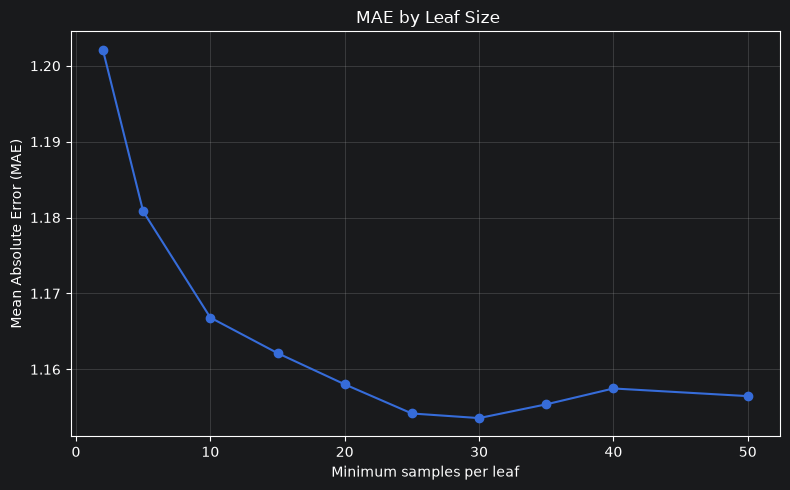

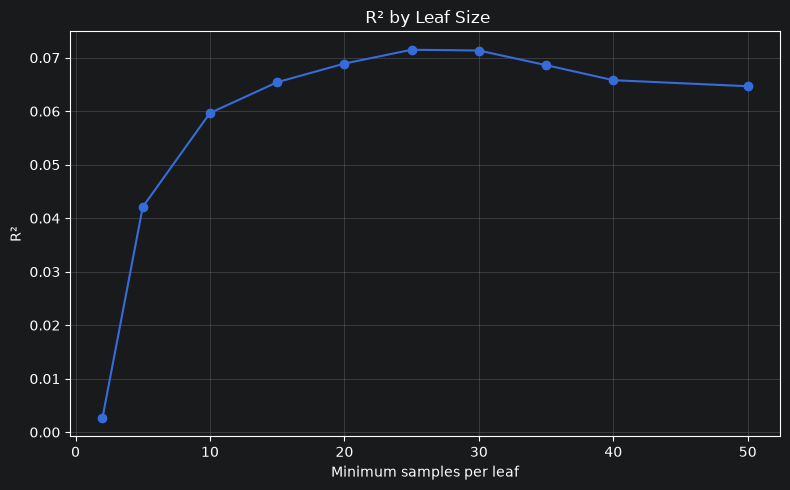

In [7]:
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold


candidate_features = [
    "city_population_within_100km",
    "nearest_city_distance_km",
    "nearest_city_500k_distance_km",
    "nearest_city_100k_distance_km",
    "nearest_large_scheduled_airport_distance_km",
    "large_scheduled_airports_within_100km",
    "city_population_within_50km",
]

# Prepare geographical features
candidate_data = final_heritage_data.loc[
    y.index, candidate_features
].apply(pd.to_numeric, errors="coerce")

cv = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluate(X_data):
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=1,
        ),
    )

    predictions = cross_val_predict(
        model, X_data, y, cv=cv, n_jobs=-1
    )

    return {
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R²": r2_score(y, predictions),
        "Median AE": median_absolute_error(y, predictions),
        "Explained variance": explained_variance_score(y, predictions),
    }

# Evaluate baseline and each geographical feature
results = [{"Added feature": "Baseline", **evaluate(X)}]

for feature in candidate_features:
    X_test = X.copy()
    X_test[feature] = candidate_data[feature]
    results.append({"Added feature": feature, **evaluate(X_test)})

results_df = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("FEATURE COMPARISON")
print(results_df.round(4).to_string(index=False))

# Select the feature with the lowest MAE, excluding baseline
best_feature = (
    results_df[results_df["Added feature"] != "Baseline"]
    .iloc[0]["Added feature"]
)

# Compare the selected model with the baseline
X_best = X.copy()
X_best[best_feature] = candidate_data[best_feature]

baseline = results_df.loc[
    results_df["Added feature"] == "Baseline"
].iloc[0]

best_scores = evaluate(X_best)

print("\nDETAILED RANDOM FOREST REPORT")
print(f"Selected feature: {best_feature}")
print(f"Properties: {len(y)}")
print(f"Number of features: {X_best.shape[1]}")
print("Cross-validation: 5-fold")
print("Trees: 300")
print("Minimum samples per leaf: 25")

print("\nMetric                 Baseline    With feature")
for metric in ["MAE", "RMSE", "R²", "Median AE", "Explained variance"]:
    print(
        f"{metric:<23} {baseline[metric]:>8.4f}    "
        f"{best_scores[metric]:>8.4f}"
    )

print("\nChange after adding feature:")
for metric in ["MAE", "RMSE", "R²"]:
    print(f"{metric}: {best_scores[metric] - baseline[metric]:+.4f}")

    import matplotlib.pyplot as plt


# Test different with the selected feature
leaf_sizes = [2, 5, 10, 15, 20, 25, 30, 35, 40, 50]

leaf_results = []

for leaf_size in leaf_sizes:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=leaf_size,
            random_state=42,
            n_jobs=1,
        ),
    )

    predictions = cross_val_predict(
        model, X_best, y, cv=cv, n_jobs=-1
    )

    leaf_results.append({
        "min_samples_leaf": leaf_size,
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R²": r2_score(y, predictions),
    })

leaf_results_df = pd.DataFrame(leaf_results)

print("\nPERFORMANCE BY MINIMUM LEAF SIZE")
print(leaf_results_df.round(4).to_string(index=False))

# Plot MAE
plt.figure(figsize=(8, 5))
plt.plot(
    leaf_results_df["min_samples_leaf"],
    leaf_results_df["MAE"],
    marker="o",
)
plt.xlabel("Minimum samples per leaf")
plt.ylabel("Mean Absolute Error (MAE)")
plt.title(f" MAE by Leaf Size")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot R²
plt.figure(figsize=(8, 5))
plt.plot(
    leaf_results_df["min_samples_leaf"],
    leaf_results_df["R²"],
    marker="o",
)
plt.xlabel("Minimum samples per leaf")
plt.ylabel("R²")
plt.title(f" R² by Leaf Size")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 30 Is best for final model comparison

In [303]:

# Cross-comparison: Dummy vs. Linear Regression vs. Random Forest
import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
    explained_variance_score,
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Best geographical feature for each model
linear_best_feature = "city_population_within_50km"
rf_best_feature = "nearest_city_100k_distance_km"

# Prepare feature sets
X_linear = X.copy()
X_linear[linear_best_feature] = candidate_data[linear_best_feature]

X_rf = X.copy()
X_rf[rf_best_feature] = candidate_data[rf_best_feature]

# Define models once
models = {
    "Dummy": (
        make_pipeline(
            SimpleImputer(strategy="median"),
            DummyRegressor(strategy="mean"),
        ),
        X,
    ),
    "Linear Regression": (
        make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LinearRegression(),
        ),
        X_linear,
    ),
    "Random Forest": (
        make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(
                n_estimators=300,
                min_samples_leaf=30,
                random_state=42,
                n_jobs=1,
            ),
        ),
        X_rf,
    ),
}

# Cross-validated model comparison
results = []

for name, (model, X_data) in models.items():
    predictions = cross_val_predict(
        model, X_data, y, cv=cv, n_jobs=-1
    )

    results.append({
        "Model": name,
        "Added feature": (
            "None" if name == "Dummy"
            else linear_best_feature if name == "Linear Regression"
            else rf_best_feature
        ),
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R²": r2_score(y, predictions),
        "Median AE": median_absolute_error(y, predictions),
        "Explained variance": explained_variance_score(y, predictions),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

# Fit Linear Regression and Random Forest on all data
# for feature interpretation (not performance evaluation)
for name in ["Linear Regression", "Random Forest"]:
    model, X_data = models[name]
    model.fit(X_data, y)

# Linear Regression coefficients, sorted by absolute magnitude
linear_model = models["Linear Regression"][0]

linear_coefficients = pd.DataFrame({
    "Feature": X_linear.columns,
    "Coefficient": linear_model.named_steps[
        "linearregression"
    ].coef_,
})

linear_coefficients["Absolute coefficient"] = (
    linear_coefficients["Coefficient"].abs()
)

linear_coefficients = linear_coefficients.sort_values(
    "Absolute coefficient", ascending=False
)

print("\nLINEAR REGRESSION COEFFICIENTS")
print(
    linear_coefficients[
        ["Feature", "Coefficient", "Absolute coefficient"]
    ].round(4).to_string(index=False)
)

# Random Forest feature importance, sorted descending
rf_model = models["Random Forest"][0]

rf_importance = pd.DataFrame({
    "Feature": X_rf.columns,
    "Importance": rf_model.named_steps[
        "randomforestregressor"
    ].feature_importances_,
}).sort_values("Importance", ascending=False)

print("\nRANDOM FOREST FEATURE IMPORTANCE")
print(rf_importance.round(4).to_string(index=False))


MODEL COMPARISON
            Model                 Added feature    MAE   RMSE      R²  Median AE  Explained variance
Linear Regression   city_population_within_50km 1.1528 1.4969  0.0717     0.9084              0.0717
    Random Forest nearest_city_100k_distance_km 1.1542 1.4970  0.0715     0.8912              0.0715
            Dummy                          None 1.2031 1.5551 -0.0020     0.9515             -0.0020

LINEAR REGRESSION COEFFICIENTS
                    Feature  Coefficient  Absolute coefficient
    years_since_inscription       0.4157                0.4157
             Continent_Asia       0.2692                0.2692
city_population_within_50km       0.1252                0.1252
          Category_Cultural       0.0856                0.0856
           Category_Natural       0.0430                0.0430
                     Danger      -0.0357                0.0357
          Continent_America      -0.0355                0.0355
          Continent_Oceania      -0.0237   